In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine = fetch_ucirepo(id=109) 
  
# data (as pandas dataframes) 
X = wine.data.features 
y = wine.data.targets

In [2]:
# metadata 
wine.metadata 

{'uci_id': 109,
 'name': 'Wine',
 'repository_url': 'https://archive.ics.uci.edu/dataset/109/wine',
 'data_url': 'https://archive.ics.uci.edu/static/public/109/data.csv',
 'abstract': 'Using chemical analysis to determine the origin of wines',
 'area': 'Physics and Chemistry',
 'tasks': ['Classification'],
 'characteristics': ['Tabular'],
 'num_instances': 178,
 'num_features': 13,
 'feature_types': ['Integer', 'Real'],
 'demographics': [],
 'target_col': ['class'],
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 1992,
 'last_updated': 'Mon Aug 28 2023',
 'dataset_doi': '10.24432/C5PC7J',
 'creators': ['Stefan Aeberhard', 'M. Forina'],
 'intro_paper': {'ID': 246,
  'type': 'NATIVE',
  'title': 'Comparative analysis of statistical pattern recognition methods in high dimensional settings',
  'authors': 'S. Aeberhard, D. Coomans, O. Vel',
  'venue': 'Pattern Recognition',
  'year': 1994,
  'journal': None,
  'DOI': '10.1016/003

In [3]:
# variable information 
wine.variables

,name,role,type,demographic,description,units,missing_values
0,class,Target,Categorical,None,None,None,no
1,Alcohol,Feature,Continuous,None,None,None,no
2,Malicacid,Feature,Continuous,None,None,None,no
3,Ash,Feature,Continuous,None,None,None,no
4,Alcalinity_of_ash,Feature,Continuous,None,None,None,no
5,Magnesium,Feature,Integer,None,None,None,no
6,Total_phenols,Feature,Continuous,None,None,None,no
7,Flavanoids,Feature,Continuous,None,None,None,no
8,Nonflavanoid_phenols,Feature,Continuous,None,None,None,no
9,Proanthocyanins,Feature,Continuous,None,None,None,no


In [4]:
# Librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos X y y que ya cargaste
df = X.copy()
df['target'] = y

In [5]:
# 1. Información básica
print("Dimensiones:", df.shape)
print("\nDescripción estadística:\n", df.describe())

Dimensiones: (178, 14)

Descripción estadística:
           Alcohol   Malicacid         Ash  Alcalinity_of_ash   Magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859        

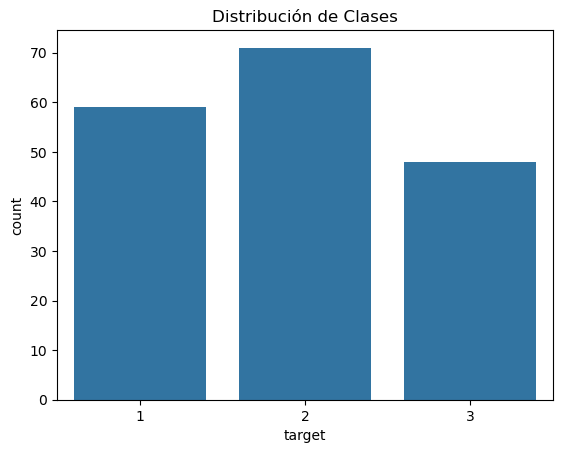

In [6]:
# 2. Distribución de clases
sns.countplot(x='target', data=df)
plt.title('Distribución de Clases')
plt.show()

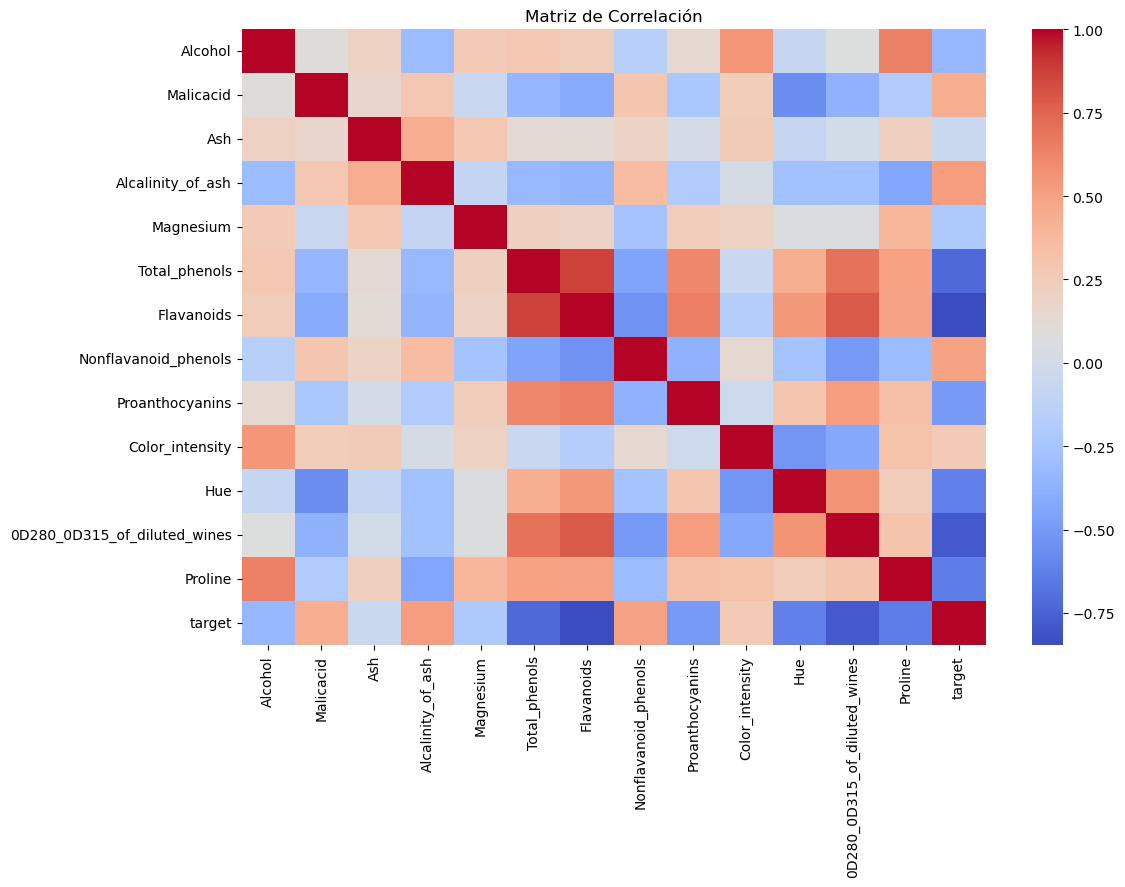

In [7]:
# 3. Matriz de correlación
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.title('Matriz de Correlación')
plt.show()

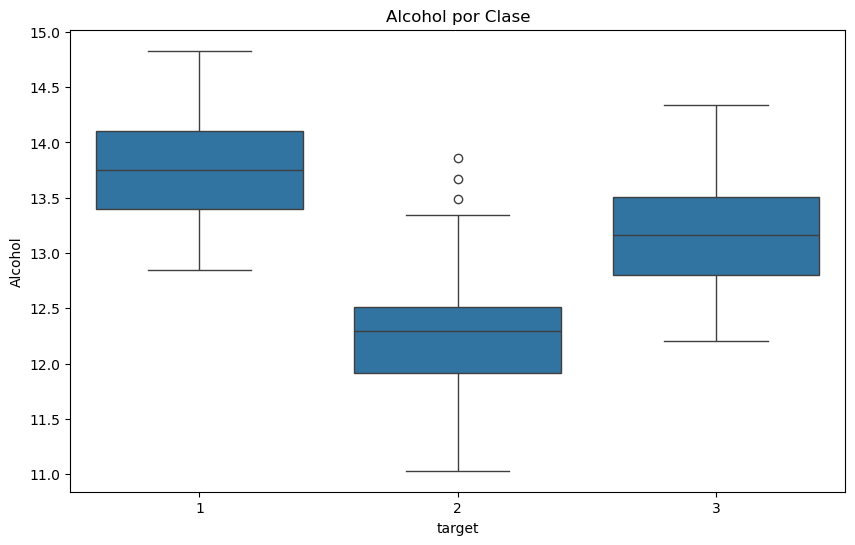

In [8]:
# 4. Boxplot para una variable clave
plt.figure(figsize=(10,6))
sns.boxplot(x='target', y='Alcohol', data=df)
plt.title('Alcohol por Clase')
plt.show()

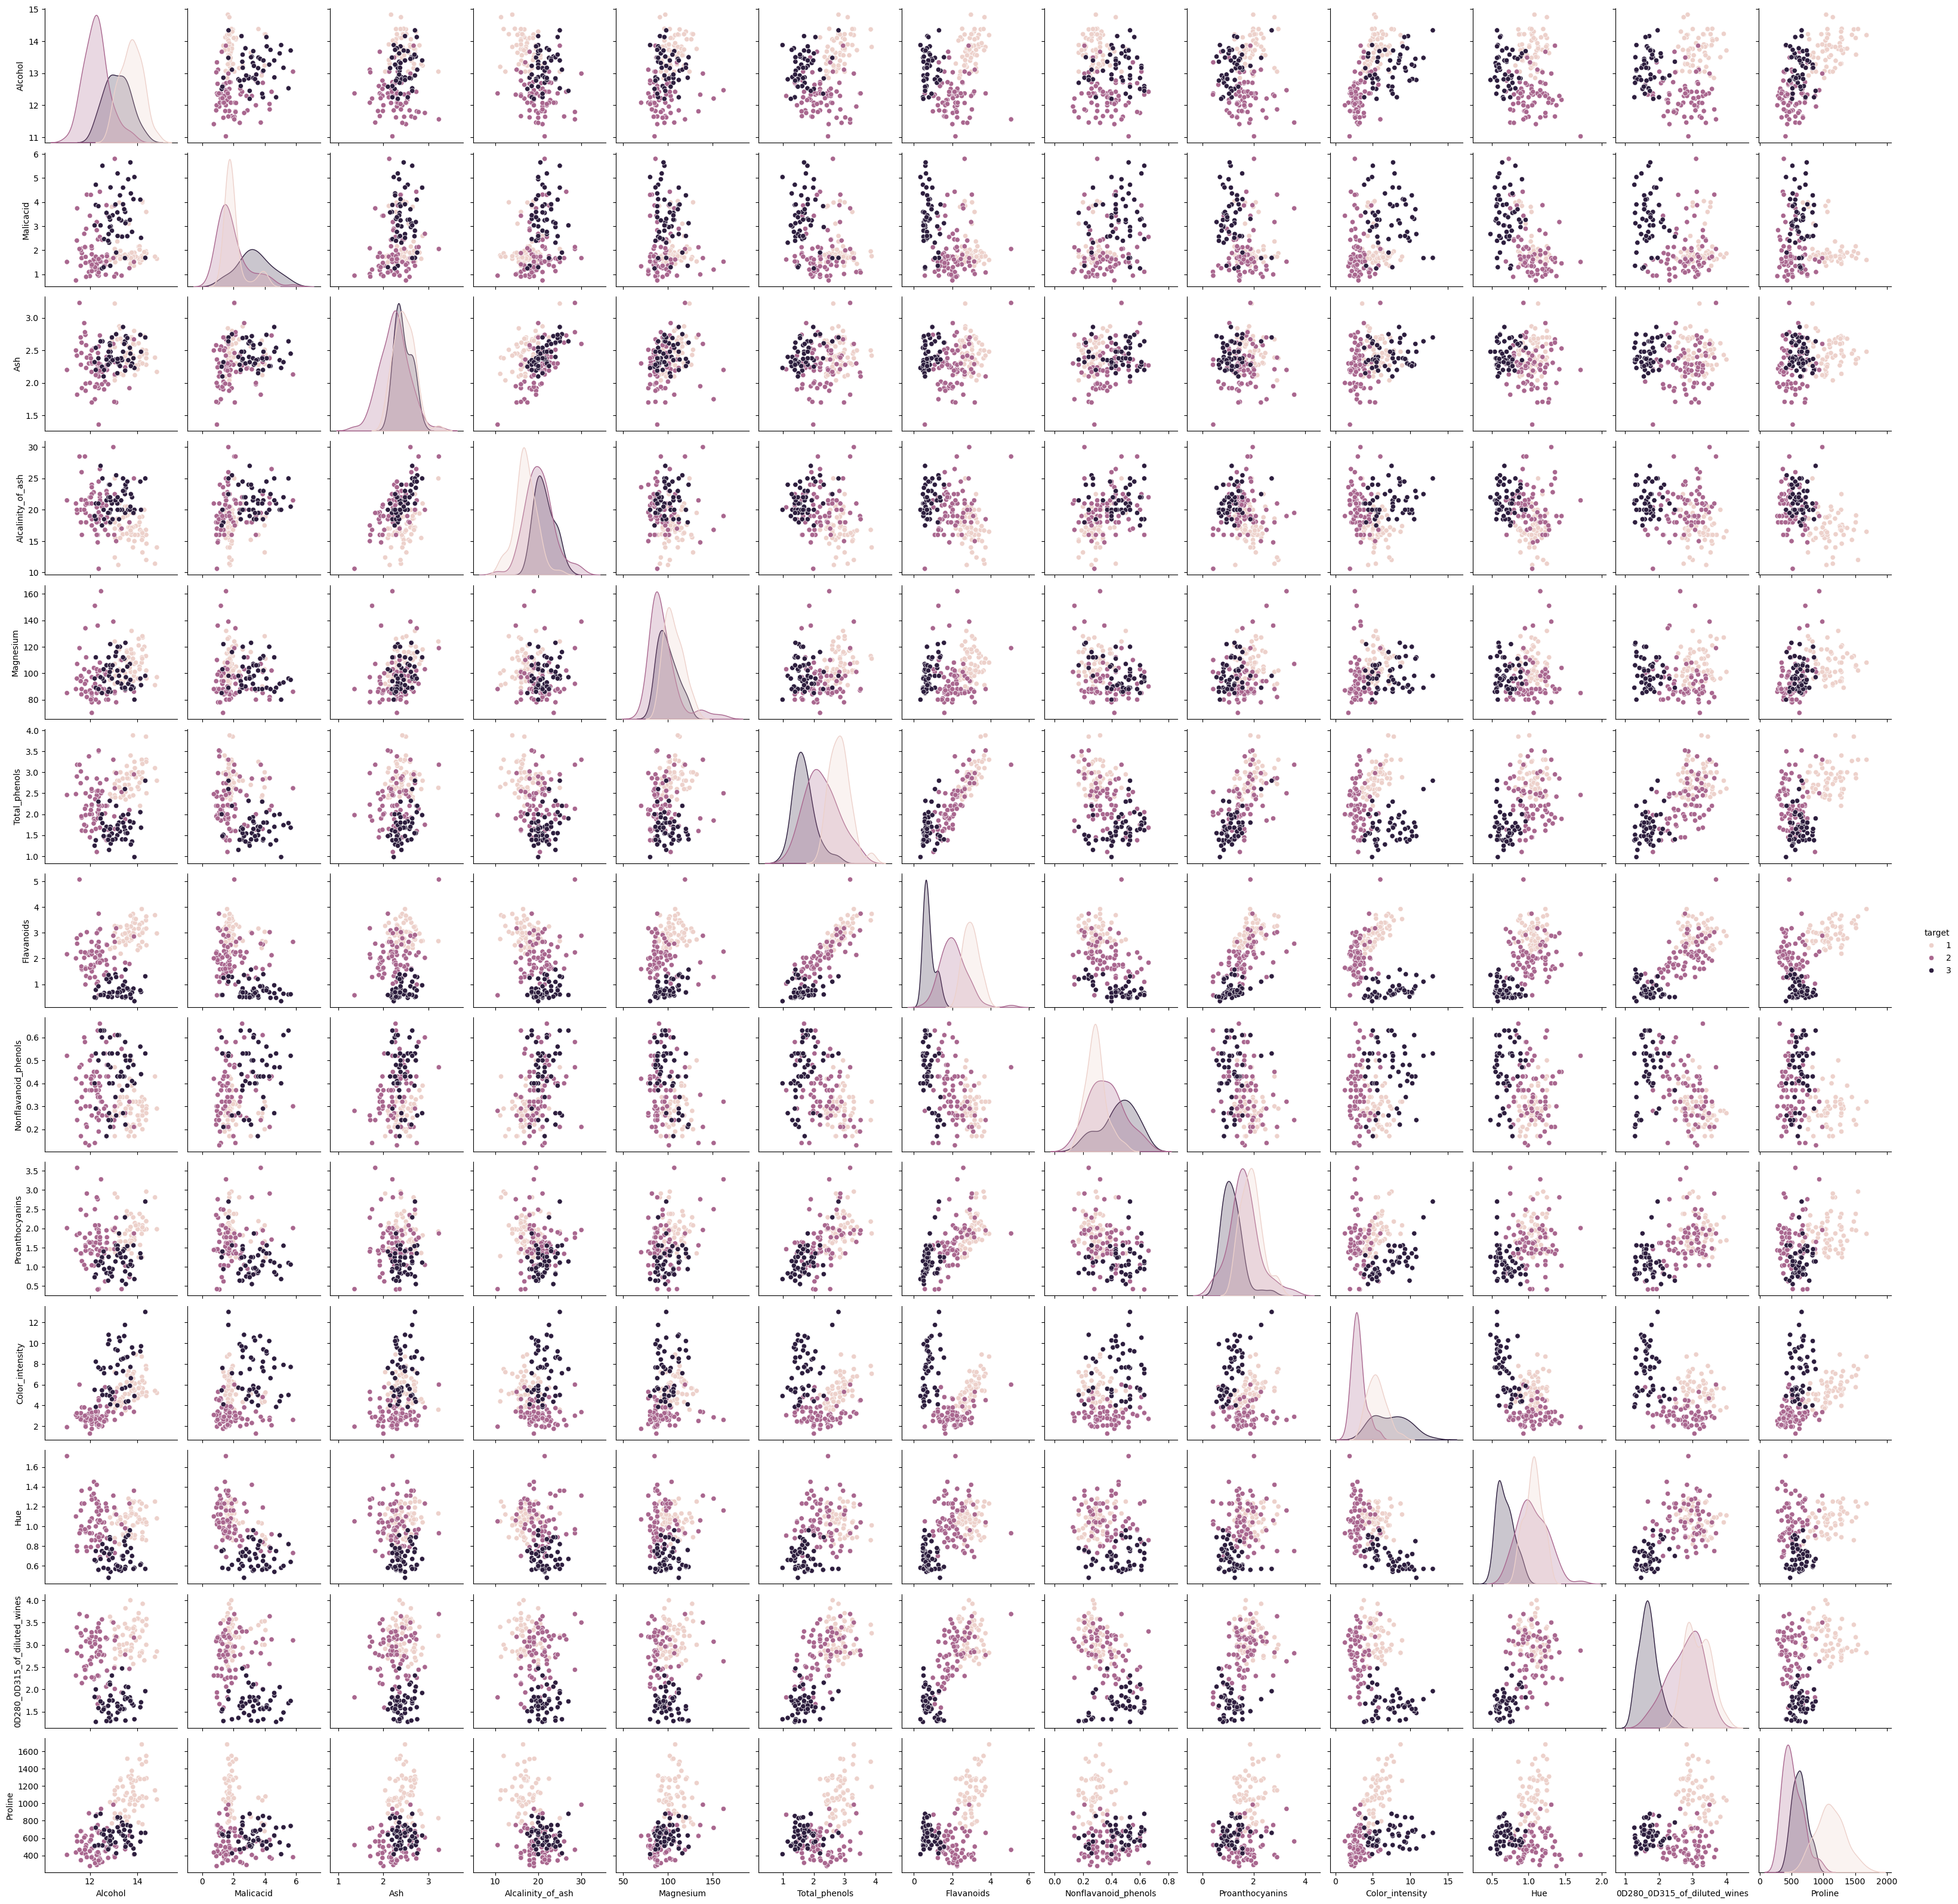

In [10]:
# 5. Pairplot para algunas variables
sns.pairplot(df, hue='target', vars= ['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash', 'Magnesium',
       'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
       'Proanthocyanins', 'Color_intensity', 'Hue',
       '0D280_0D315_of_diluted_wines', 'Proline'])
plt.show()

In [12]:
df.columns

Index(['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash', 'Magnesium',
       'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
       'Proanthocyanins', 'Color_intensity', 'Hue',
       '0D280_0D315_of_diluted_wines', 'Proline', 'target'],
      dtype='object')

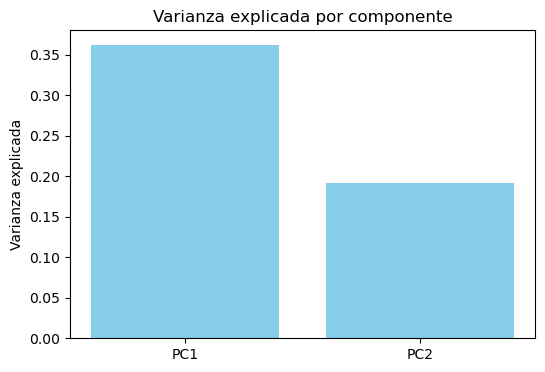

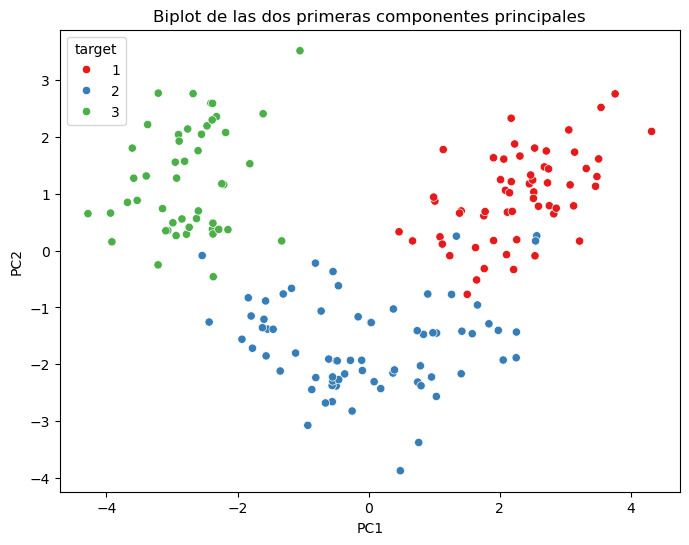

Cargas (loadings):
                                   PC1       PC2
Alcohol                       0.144329  0.483652
Malicacid                    -0.245188  0.224931
Ash                          -0.002051  0.316069
Alcalinity_of_ash            -0.239320 -0.010591
Magnesium                     0.141992  0.299634
Total_phenols                 0.394661  0.065040
Flavanoids                    0.422934 -0.003360
Nonflavanoid_phenols         -0.298533  0.028779
Proanthocyanins               0.313429  0.039302
Color_intensity              -0.088617  0.529996
Hue                           0.296715 -0.279235
0D280_0D315_of_diluted_wines  0.376167 -0.164496
Proline                       0.286752  0.364903


In [13]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Supongamos que ya tienes X y y cargados
df = X.copy()
df['target'] = y

# 1. Estandarizar las variables (solo X)
features = X.columns
X_scaled = StandardScaler().fit_transform(df[features])

# 2. Aplicar PCA
pca = PCA(n_components=2)  # puedes cambiar el número de componentes
principal_components = pca.fit_transform(X_scaled)

# 3. Crear DataFrame con las componentes
principal_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
principal_df['target'] = df['target']

# 4. Gráfico de varianza explicada
plt.figure(figsize=(6,4))
plt.bar(['PC1', 'PC2'], pca.explained_variance_ratio_, color='skyblue')
plt.ylabel('Varianza explicada')
plt.title('Varianza explicada por componente')
plt.show()

# 5. Biplot (scatter de PC1 vs PC2)
plt.figure(figsize=(8,6))
sns.scatterplot(data=principal_df, x='PC1', y='PC2', hue='target', palette='Set1')
plt.title('Biplot de las dos primeras componentes principales')
plt.show()

# 6. Mostrar cargas (loadings)
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
print("Cargas (loadings):")
print(loadings)

In [14]:

# 3. Autovalores (varianza explicada * número de observaciones - opcional)
autovalores = pca.explained_variance_
print("Autovalores (eigenvalues):")
print(autovalores)

# 4. Autovectores (componentes principales)
autovectores = pca.components_
print("\nAutovectores (eigenvectors):")
print(pd.DataFrame(autovectores, columns=features))

# 5. Varianza explicada por cada componente
print("\nProporción de varianza explicada:")
print(pca.explained_variance_ratio_)


Autovalores (eigenvalues):
[4.73243698 2.51108093]

Autovectores (eigenvectors):
    Alcohol  Malicacid       Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
0  0.144329  -0.245188 -0.002051          -0.239320   0.141992       0.394661   
1  0.483652   0.224931  0.316069          -0.010591   0.299634       0.065040   

   Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity  \
0    0.422934             -0.298533         0.313429        -0.088617   
1   -0.003360              0.028779         0.039302         0.529996   

        Hue  0D280_0D315_of_diluted_wines   Proline  
0  0.296715                      0.376167  0.286752  
1 -0.279235                     -0.164496  0.364903  

Proporción de varianza explicada:
[0.36198848 0.1920749 ]
